# 7 Регрессия

## 7.1 Создание регрессора одной переменной

In [29]:
#!/usr/bin/env python3
import pickle

import matplotlib.pyplot as plt
import numpy as np
import sklearn.metrics as sm
from sklearn import linear_model

In [30]:
# Входной файл, содержащий данные
input_file = 'data/data_singlevar_regr.txt'
# Загрузка данных
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]

In [31]:
# Разбивка данных на обучающий и тестовый наборы
num_training = int(0.8 * len(X))
num_test = len(X) - num_training
# Тренировочные данные
X_train, y_train = X[:num_training], y[:num_training]
# Тестовые данные
X_test, y_test = X[num_training:], y[num_training:]

In [32]:
# Создание объекта линейного регрессора
regressor = linear_model.LinearRegression()
# Обучение модели с использованием обучающего набора
regressor.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.69]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.027
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[20.43]


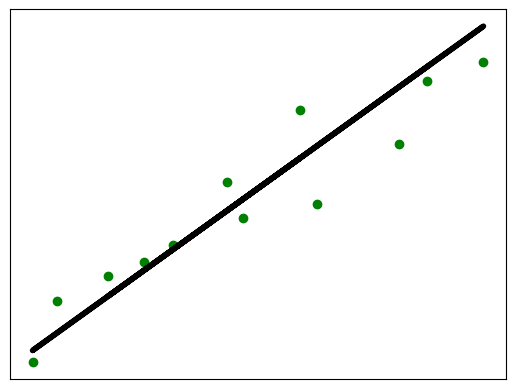

In [33]:
# Прогнозирование результата
y_test_pred = regressor.predict(X_test)
# Построение графика
plt.scatter(X_test, y_test, color='green')
plt.plot(X_test, y_test_pred, color='black', linewidth=4)
plt.xticks(())
plt.yticks(())
plt.show()

In [34]:
# Вычисление метрик
print("Linear regressor performance:")
print("Mean absolute error =", round(sm.mean_absolute_error(y_test, y_test_pred), 2))
print("Mean squared error =", round(sm.mean_squared_error(y_test, y_test_pred), 2))
print("Median absolute error =", round(sm.median_absolute_error(y_test, y_test_pred), 2))
print("Explain variance score =", round(sm.explained_variance_score(y_test, y_test_pred), 2))
print("R2 score =", round(sm.r2_score(y_test, y_test_pred), 2))

Linear regressor performance:
Mean absolute error = 0.59
Mean squared error = 0.49
Median absolute error = 0.51
Explain variance score = 0.86
R2 score = 0.86


In [35]:
# Файл для сохранения модели
output_model_file = 'model.pkl'
# Сохранение модели
with open(output_model_file, 'wb') as f:
    pickle.dump(regressor, f)

In [36]:
# Загрузка модели
with open(output_model_file, 'rb') as f:
    regressor_model = pickle.load(f)
# Получение прогноза на тестовом наборе данных
y_test_pred_new = regressor_model.predict(X_test)
print("\nNew mean absolute error =", round(sm.mean_absolute_error(y_test, y_test_pred_new), 2))


New mean absolute error = 0.59


## 7.2 Создание многомерного регрессора

In [37]:
import numpy as np
import sklearn.metrics as sm
from sklearn import linear_model
from sklearn.preprocessing import PolynomialFeatures

In [38]:
# Входной файл, содержащий данные
input_file = 'data/data_multivar_regr.txt'
# Загрузка данных
data = np.loadtxt(input_file, delimiter=',')
X, y = data[:, :-1], data[:, -1]

In [39]:
# Разбивка данных на обучающий и тестовый наборы
num_training = int(0.8 * len(X))
num_test = len(X) - num_training
# Тренировочные данные
X_train, y_train = X[:num_training], y[:num_training]
# Тестовые данные
X_test, y_test = X[num_training:], y[num_training:]

### Линейная регрессия

In [40]:
# Создание модели линейного регрессора
linear_regressor = linear_model.LinearRegression()

# Обучение модели с использованием обучающих наборов
linear_regressor.fit(X_train, y_train)

# Прогнозирование результата
y_test_pred = linear_regressor.predict(X_test)

# Измерение метрик
print("Linear Regressor performance:")
print("Mean absolute error =", round(sm.mean_absolute_error(y_test, y_test_pred), 2))
print("Mean squared error =", round(sm.mean_squared_error(y_test, y_test_pred), 2))
print("Median absolute error =", round(sm.median_absolute_error(y_test, y_test_pred), 2))
print("Explained variance score =", round(sm.explained_variance_score(y_test, y_test_pred), 2))
print("R2 score =", round(sm.r2_score(y_test, y_test_pred), 2))

Linear Regressor performance:
Mean absolute error = 3.58
Mean squared error = 20.31
Median absolute error = 2.99
Explained variance score = 0.86
R2 score = 0.86


In [ ]:
# Полиномиальная регрессия
polynomial = PolynomialFeatures(degree=10)
X_train_transformed = polynomial.fit_transform(X_train)
X_test_transformed = polynomial.transform(X_test)

# Линейный регрессор
poly_linear_model = linear_model.LinearRegression()
poly_linear_model.fit(X_train_transformed, y_train)

# Прогнозирование результата
y_test_pred = poly_linear_model.predict(X_test_transformed)

# Измерение метрик
print("Linear Regressor performance:")
print("Mean absolute error =", round(sm.mean_absolute_error(y_test, y_test_pred), 2))
print("Mean squared error =", round(sm.mean_squared_error(y_test, y_test_pred), 2))
print("Median absolute error =", round(sm.median_absolute_error(y_test, y_test_pred), 2))
print("Explained variance score =", round(sm.explained_variance_score(y_test, y_test_pred), 2))
print("R2 score =", round(sm.r2_score(y_test, y_test_pred), 2))

Linear Regressor performance:
Mean absolute error = 11.19
Mean squared error = 907.66
Median absolute error = 5.09
Explained variance score = -4.9
R2 score = -5.04


In [ ]:
# Тестовая точка
datapoint = [[7.75, 6.35, 5.56]]
# в полиномиальном представлении
poly_datapoint = polynomial.transform(datapoint)

print("\nLinear regression:\n", linear_regressor.predict(datapoint))
print("\nPolynomial regression:\n", poly_linear_model.predict(poly_datapoint))


Linear regression:
 [36.05286276]

Polynomial regression:
 [31.63944054]
